# 02 · Aspect-level sentiment classifiers and class imbalance

DeBERTa-v3-small fine-tuned on aspect–sentiment pairs from all five domains. Five ways of handling the class imbalance are compared, each trained with three seeds (42, 153, 650):

| Method | Description |
|---|---|
| No handling | Plain cross-entropy |
| Class weights | Cross-entropy weighted by inverse class frequency (clamped at 3) |
| Random oversampling | Minority classes duplicated to 30% of the majority class |
| Focal loss | Cross-entropy scaled by (1 − p)<sup>2</sup> |
| Balanced bagging | Five models, each trained on all minority pairs and a disjoint fifth of the majority class; probabilities averaged |

Completed runs are skipped, so the notebook can be re-run after a disconnection.

In [1]:
PROJECT_DIR = "/content/drive/MyDrive/aspect-insight"

In [2]:
import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    PROJECT_DIR = os.path.abspath("..")
os.chdir(PROJECT_DIR)
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
print(os.getcwd())

Mounted at /content/drive
/content/drive/MyDrive/aspect-insight


In [3]:
!pip -q install -r requirements.txt
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB


## Training

In [4]:
!python scripts/train_classifiers.py --config configs/classifiers.yaml

Device: NVIDIA A100-SXM4-40GB
Train 19,921 pairs (NEG 4,329 / NEU 455 / POS 15,137)
Dev   2,726 pairs (NEG 575 / NEU 68 / POS 2,083)
Test  5,479 pairs (NEG 1,197 / NEU 102 / POS 4,180)
[none seed 42] already complete, skipped
[class_weights seed 42] already complete, skipped
[oversample seed 42] already complete, skipped
[focal seed 42] already complete, skipped
[bagging seed 42 member 1/5] training on 9,136 pairs (NEG 5,268 / NEU 621 / POS 3,247)
config.json: 100% 578/578 [00:00<00:00, 3.15MB/s]
tokenizer_config.json: 100% 52.0/52.0 [00:00<00:00, 295kB/s]
spm.model: 100% 2.46M/2.46M [00:00<00:00, 13.6MB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
pytorch_model.bin: 100% 286M/286M [00:02<00:00, 120MB/s]
Loading weights: 100% 102/102 [00:00<00:00, 13965.04it/s]
[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta

## Evaluation

In [5]:
!python scripts/evaluate_classifiers.py

# Aspect-level sentiment: class-imbalance study

Test pairs: 5,479 (all five domains). Values are mean ± standard deviation over seeds.

| Method | Seeds | Accuracy | Macro-F1 | Neutral F1 | Conflicting acc | ECE | Models | Train (min) | ms/pair |
|---|---|---|---|---|---|---|---|---|---|
| No handling | 3 | 0.929 ± 0.005 | 0.746 ± 0.011 | 0.410 ± 0.027 | 0.734 ± 0.003 | 0.050 | 1 | 8.1 | 0.77 |
| Class weights | 3 | 0.930 ± 0.000 | 0.756 ± 0.007 | 0.438 ± 0.019 | 0.737 ± 0.015 | 0.053 | 1 | 8.1 | 0.78 |
| Random oversampling | 3 | 0.928 ± 0.001 | 0.750 ± 0.004 | 0.426 ± 0.016 | 0.743 ± 0.005 | 0.056 | 1 | 10.1 | 0.78 |
| Focal loss | 3 | 0.932 ± 0.002 | 0.759 ± 0.013 | 0.445 ± 0.035 | 0.742 ± 0.008 | 0.025 | 1 | 8.1 | 0.78 |
| Balanced bagging (ensemble) | 3 | 0.911 ± 0.001 | 0.725 ± 0.002 | 0.381 ± 0.005 | 0.682 ± 0.008 | 0.038 | 5 | 13.6 | 2.97 |
| Balanced bagging (one member) | 3 | 0.902 ± 0.007 | 0.709 ± 0.010 | 0.349 ± 0.021 | 0.668 ± 0.022 | 0.064 | 1 | 2.7 | 0.59 |

## Macro-F

In [6]:
from IPython.display import Image, Markdown, display

RESULTS = "outputs/results/classifiers"
display(Markdown(open(f"{RESULTS}/summary.md", encoding="utf-8").read()))

# Aspect-level sentiment: class-imbalance study

Test pairs: 5,479 (all five domains). Values are mean ± standard deviation over seeds.

| Method | Seeds | Accuracy | Macro-F1 | Neutral F1 | Conflicting acc | ECE | Models | Train (min) | ms/pair |
|---|---|---|---|---|---|---|---|---|---|
| No handling | 3 | 0.929 ± 0.005 | 0.746 ± 0.011 | 0.410 ± 0.027 | 0.734 ± 0.003 | 0.050 | 1 | 8.1 | 0.77 |
| Class weights | 3 | 0.930 ± 0.000 | 0.756 ± 0.007 | 0.438 ± 0.019 | 0.737 ± 0.015 | 0.053 | 1 | 8.1 | 0.78 |
| Random oversampling | 3 | 0.928 ± 0.001 | 0.750 ± 0.004 | 0.426 ± 0.016 | 0.743 ± 0.005 | 0.056 | 1 | 10.1 | 0.78 |
| Focal loss | 3 | 0.932 ± 0.002 | 0.759 ± 0.013 | 0.445 ± 0.035 | 0.742 ± 0.008 | 0.025 | 1 | 8.1 | 0.78 |
| Balanced bagging (ensemble) | 3 | 0.911 ± 0.001 | 0.725 ± 0.002 | 0.381 ± 0.005 | 0.682 ± 0.008 | 0.038 | 5 | 13.6 | 2.97 |
| Balanced bagging (one member) | 3 | 0.902 ± 0.007 | 0.709 ± 0.010 | 0.349 ± 0.021 | 0.668 ± 0.022 | 0.064 | 1 | 2.7 | 0.59 |

## Macro-F1 per domain (mean over seeds)

| Method | Books | Clothing | Hotel | Laptop | Restaurant |
|---|---|---|---|---|---|
| No handling | 0.696 | 0.708 | 0.910 | 0.764 | 0.762 |
| Class weights | 0.712 | 0.682 | 0.931 | 0.768 | 0.780 |
| Random oversampling | 0.705 | 0.663 | 0.920 | 0.768 | 0.771 |
| Focal loss | 0.712 | 0.690 | 0.926 | 0.771 | 0.785 |
| Balanced bagging (ensemble) | 0.696 | 0.680 | 0.906 | 0.727 | 0.747 |
| Balanced bagging (one member) | 0.659 | 0.669 | 0.900 | 0.719 | 0.731 |

## McNemar test against Class weights (per seed)

| Method | Seed | Only this method correct | Only class weights correct | p |
|---|---|---|---|---|
| Balanced bagging (ensemble) | 42 | 53 | 161 | 7.47e-14 |
| Balanced bagging (ensemble) | 153 | 90 | 194 | 6.39e-10 |
| Balanced bagging (ensemble) | 650 | 64 | 163 | 3.83e-11 |
| Balanced bagging (one member) | 42 | 71 | 204 | 4.49e-16 |
| Balanced bagging (one member) | 153 | 93 | 211 | 1.07e-11 |
| Balanced bagging (one member) | 650 | 74 | 226 | 4.72e-19 |
| Focal loss | 42 | 70 | 45 | 0.0248 |
| Focal loss | 153 | 74 | 69 | 0.738 |
| Focal loss | 650 | 62 | 64 | 0.929 |
| No handling | 42 | 87 | 80 | 0.643 |
| No handling | 153 | 82 | 72 | 0.468 |
| No handling | 650 | 63 | 100 | 0.00466 |
| Random oversampling | 42 | 89 | 105 | 0.281 |
| Random oversampling | 153 | 92 | 100 | 0.614 |
| Random oversampling | 650 | 75 | 89 | 0.31 |

## 95% bootstrap intervals (seed 42)

| Method | Macro-F1 | Neutral F1 |
|---|---|---|
| No handling | 0.740 [0.709, 0.769] | 0.390 [0.305, 0.471] |
| Class weights | 0.764 [0.736, 0.790] | 0.459 [0.373, 0.536] |
| Random oversampling | 0.754 [0.723, 0.782] | 0.443 [0.357, 0.523] |
| Focal loss | 0.773 [0.742, 0.803] | 0.484 [0.393, 0.564] |
| Balanced bagging (ensemble) | 0.724 [0.695, 0.750] | 0.380 [0.298, 0.455] |
| Balanced bagging (one member) | 0.718 [0.688, 0.749] | 0.379 [0.291, 0.465] |


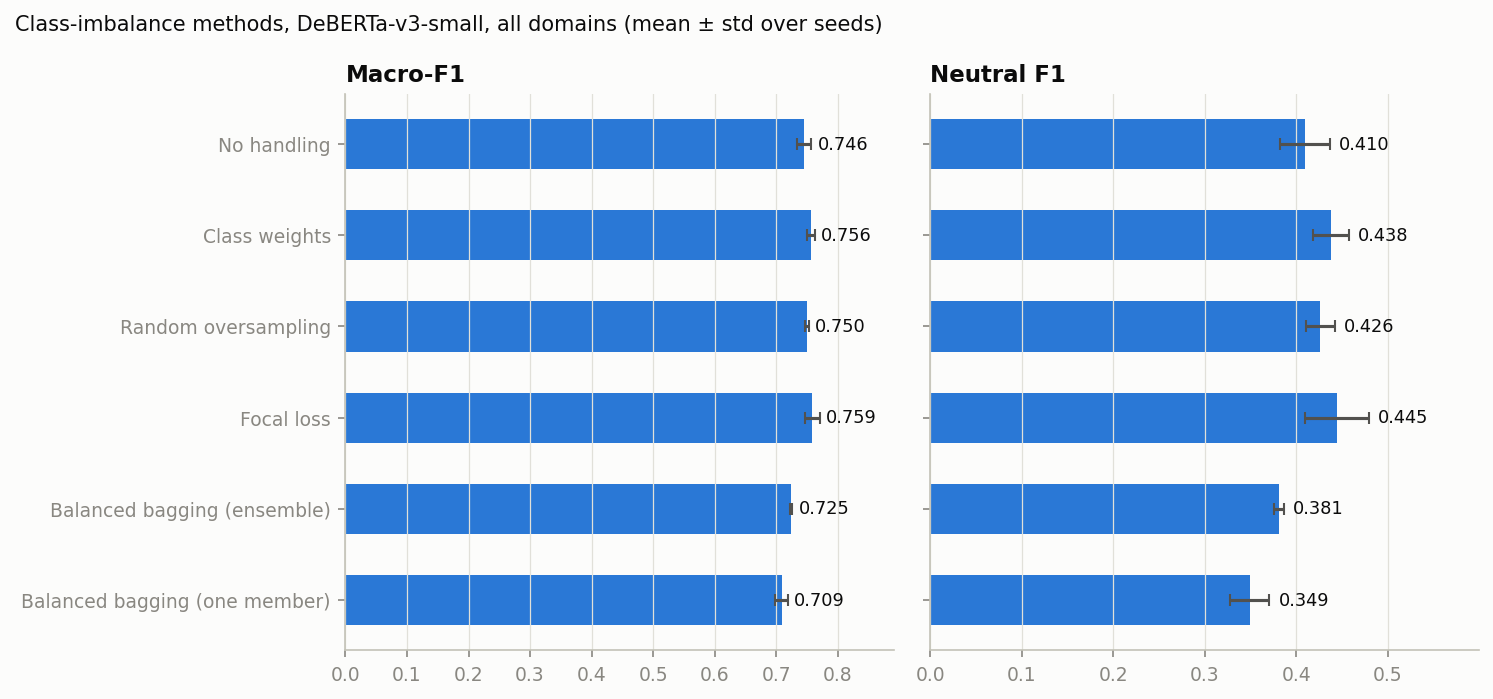

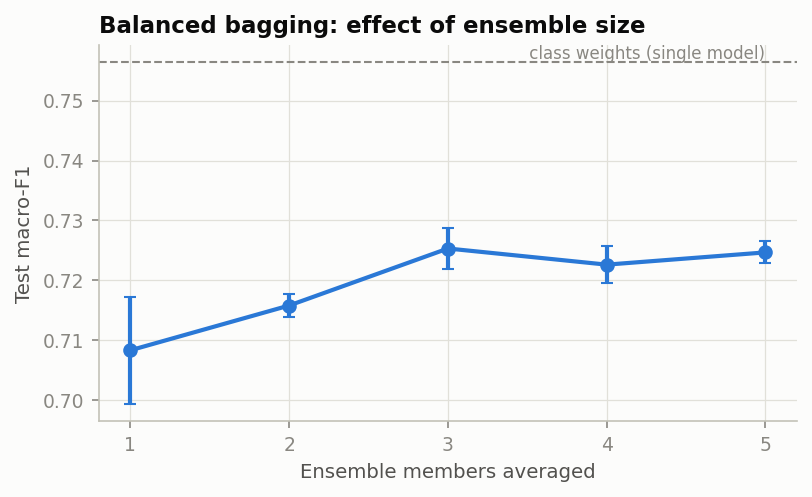

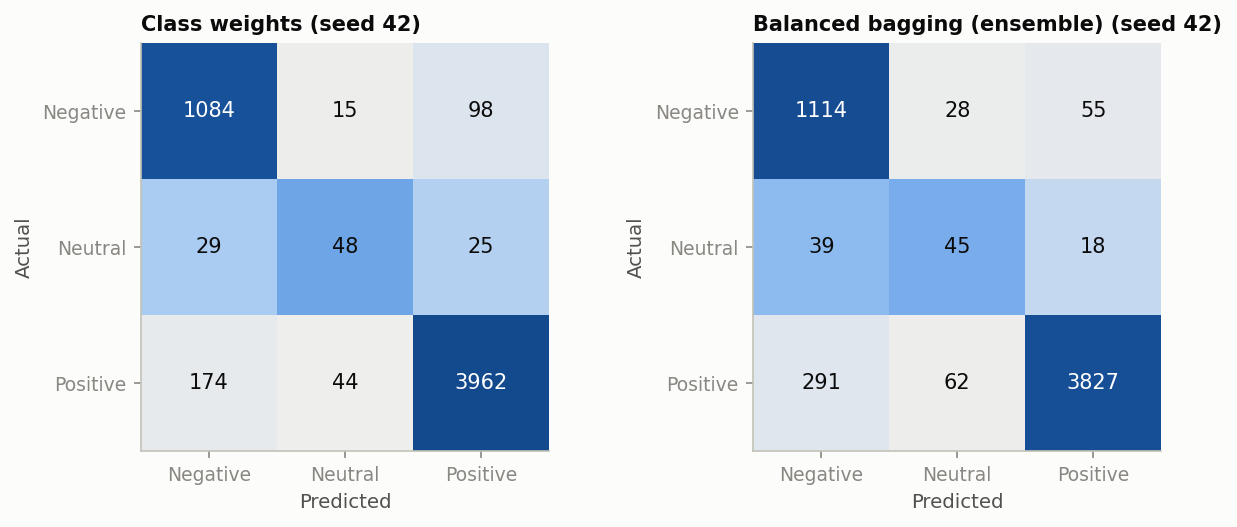

In [7]:
for name in ["imbalance_methods", "ensemble_size", "confusion_matrices"]:
    display(Image(f"{RESULTS}/figures/{name}.png"))

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
